# MODEL DATA PREPARATION

In [17]:
#LOADING DATA
import pandas as pd
from pathlib import Path

pd.set_option("display.max_columns", None)

DATA_PATH = Path("../data/processed/clinical_features.csv")

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 101,766
Columns: 29


,patient_id,encounter_id,age_midpoint,gender,race,admission_type,admission_source,discharge_disposition,length_of_stay,previous_inpatient_visits,previous_outpatient_visits,previous_emergency_visits,primary_diagnosis,secondary_diagnosis,tertiary_diagnosis,diagnosis_count,lab_procedure_count,procedure_count,medication_count,hba1c_result,glucose_result,insulin_status,diabetes_medication,readmitted_30_days,primary_diagnosis_category,secondary_diagnosis_category,tertiary_diagnosis_category,total_previous_visits,has_previous_inpatient_visit
0,8222157,2278392,5,Female,Caucasian,Unmapped:6,Physician Referral,Not Mapped,1,0,0,0,250.83,NaN,NaN,1,41,0,1,NaN,NaN,No,No,False,Diabetes,Other,Other,0,0
1,55629189,149190,15,Female,Caucasian,Emergency,Emergency Room,Discharged to home,3,0,0,0,276,250.01,255,9,59,0,18,NaN,NaN,Up,Yes,False,Endocrine,Diabetes,Endocrine,0,0
2,86047875,64410,25,Female,AfricanAmerican,Emergency,Emergency Room,Discharged to home,2,1,2,0,648,250,V27,6,11,5,13,NaN,NaN,No,Yes,False,Pregnancy,Diabetes,Supplementary,3,1
3,82442376,500364,35,Male,Caucasian,Emergency,Emergency Room,Discharged to home,2,0,0,0,8,250.43,403,7,44,1,16,NaN,NaN,Up,Yes,False,Infectious,Diabetes,Circulatory,0,0
4,42519267,16680,45,Male,Caucasian,Emergency,Emergency Room,Discharged to home,1,0,0,0,197,157,250,5,51,0,8,NaN,NaN,Steady,Yes,False,Neoplasms,Neoplasms,Diabetes,0,0


In [18]:
#INSPECTING ALL COLUMNS
df.columns.tolist()

['patient_id',
 'encounter_id',
 'age_midpoint',
 'gender',
 'race',
 'admission_type',
 'admission_source',
 'discharge_disposition',
 'length_of_stay',
 'previous_inpatient_visits',
 'previous_outpatient_visits',
 'previous_emergency_visits',
 'primary_diagnosis',
 'secondary_diagnosis',
 'tertiary_diagnosis',
 'diagnosis_count',
 'lab_procedure_count',
 'procedure_count',
 'medication_count',
 'hba1c_result',
 'glucose_result',
 'insulin_status',
 'diabetes_medication',
 'readmitted_30_days',
 'primary_diagnosis_category',
 'secondary_diagnosis_category',
 'tertiary_diagnosis_category',
 'total_previous_visits',
 'has_previous_inpatient_visit']

In [19]:
#SEPARATING THE TARGET
TARGET = "readmitted_30_days"

y = df[TARGET].astype(int)

y.value_counts()

readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64

In [20]:
#REMOVING IDENTIFIERS
IDENTIFIER_COLUMNS = [
    "patient_id",
    "encounter_id",
]

X = df.drop(
    columns=IDENTIFIER_COLUMNS + [TARGET]
)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (101766, 26)
y shape: (101766,)


In [21]:
#INSPECTING DATATYPES
X.dtypes

age_midpoint                    int64
gender                            str
race                              str
admission_type                    str
admission_source                  str
discharge_disposition             str
length_of_stay                  int64
previous_inpatient_visits       int64
previous_outpatient_visits      int64
previous_emergency_visits       int64
primary_diagnosis                 str
secondary_diagnosis               str
tertiary_diagnosis                str
diagnosis_count                 int64
lab_procedure_count             int64
procedure_count                 int64
medication_count                int64
hba1c_result                      str
glucose_result                    str
insulin_status                    str
diabetes_medication               str
primary_diagnosis_category        str
secondary_diagnosis_category      str
tertiary_diagnosis_category       str
total_previous_visits           int64
has_previous_inpatient_visit    int64
dtype: objec

In [22]:
X.select_dtypes(include="object").columns.tolist()

C:\Users\nolee\AppData\Local\Temp\ipykernel_38792\1679899076.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X.select_dtypes(include="object").columns.tolist()


['gender',
 'race',
 'admission_type',
 'admission_source',
 'discharge_disposition',
 'primary_diagnosis',
 'secondary_diagnosis',
 'tertiary_diagnosis',
 'hba1c_result',
 'glucose_result',
 'insulin_status',
 'diabetes_medication',
 'primary_diagnosis_category',
 'secondary_diagnosis_category',
 'tertiary_diagnosis_category']

In [23]:
X.select_dtypes(exclude="object").columns.tolist()

['age_midpoint',
 'length_of_stay',
 'previous_inpatient_visits',
 'previous_outpatient_visits',
 'previous_emergency_visits',
 'diagnosis_count',
 'lab_procedure_count',
 'procedure_count',
 'medication_count',
 'total_previous_visits',
 'has_previous_inpatient_visit']

In [24]:
#CHECKING MISSING VALUES
missing = (
    X.isna()
    .sum()
    .sort_values(ascending=False)
)

missing[missing > 0]

glucose_result         96420
hba1c_result           84748
race                    2273
tertiary_diagnosis      1423
secondary_diagnosis      358
primary_diagnosis         21
dtype: int64

## Leakage and Patient-Level Split Analysis

In [25]:
# Check how many patients have multiple encounters

patient_counts = df["patient_id"].value_counts()

print(f"Unique patients: {df['patient_id'].nunique():,}")
print(f"Total encounters: {len(df):,}")
print(f"Patients with multiple encounters: {(patient_counts > 1).sum():,}")
print(f"Maximum encounters for one patient: {patient_counts.max()}")

Unique patients: 71,518
Total encounters: 101,766
Patients with multiple encounters: 16,773
Maximum encounters for one patient: 40


In [27]:
#INSPECTING FEATURE TYPES
categorical_columns = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("CATEGORICAL FEATURES:")
for col in categorical_columns:
    print(f"  - {col}")

print("\nNUMERICAL FEATURES:")
for col in numerical_columns:
    print(f"  - {col}")

CATEGORICAL FEATURES:
  - gender
  - race
  - admission_type
  - admission_source
  - discharge_disposition
  - primary_diagnosis
  - secondary_diagnosis
  - tertiary_diagnosis
  - hba1c_result
  - glucose_result
  - insulin_status
  - diabetes_medication
  - primary_diagnosis_category
  - secondary_diagnosis_category
  - tertiary_diagnosis_category

NUMERICAL FEATURES:
  - age_midpoint
  - length_of_stay
  - previous_inpatient_visits
  - previous_outpatient_visits
  - previous_emergency_visits
  - diagnosis_count
  - lab_procedure_count
  - procedure_count
  - medication_count
  - total_previous_visits
  - has_previous_inpatient_visit


In [28]:
RAW_DIAGNOSIS_COLUMNS = [
    "primary_diagnosis",
    "secondary_diagnosis",
    "tertiary_diagnosis",
]

## Baseline Model V1 Feature Selection

For the baseline model, raw ICD-9 diagnosis codes are excluded in favor of
the engineered diagnosis categories. Patient and encounter identifiers are
retained only for data splitting and are not provided to the model.

In [29]:
# Columns that must not be used as predictors

IDENTIFIER_COLUMNS = [
    "patient_id",
    "encounter_id",
]

RAW_DIAGNOSIS_COLUMNS = [
    "primary_diagnosis",
    "secondary_diagnosis",
    "tertiary_diagnosis",
]

TARGET = "readmitted_30_days"

MODEL_EXCLUDED_COLUMNS = (
    IDENTIFIER_COLUMNS
    + RAW_DIAGNOSIS_COLUMNS
    + [TARGET]
)

model_features = [
    col for col in df.columns
    if col not in MODEL_EXCLUDED_COLUMNS
]

print(f"Model V1 features: {len(model_features)}")

for feature in model_features:
    print(f"  - {feature}")

Model V1 features: 23
  - age_midpoint
  - gender
  - race
  - admission_type
  - admission_source
  - discharge_disposition
  - length_of_stay
  - previous_inpatient_visits
  - previous_outpatient_visits
  - previous_emergency_visits
  - diagnosis_count
  - lab_procedure_count
  - procedure_count
  - medication_count
  - hba1c_result
  - glucose_result
  - insulin_status
  - diabetes_medication
  - primary_diagnosis_category
  - secondary_diagnosis_category
  - tertiary_diagnosis_category
  - total_previous_visits
  - has_previous_inpatient_visit


## Patient-Level Train/Test Split

In [30]:
from sklearn.model_selection import GroupShuffleSplit

X = df[model_features].copy()
y = df[TARGET].astype(int)

groups = df["patient_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_patient_ids = set(
    df.iloc[train_idx]["patient_id"]
)

test_patient_ids = set(
    df.iloc[test_idx]["patient_id"]
)

print("Training encounters:", len(X_train))
print("Testing encounters:", len(X_test))

print("\nTraining patients:", len(train_patient_ids))
print("Testing patients:", len(test_patient_ids))

print(
    "\nPatients appearing in BOTH sets:",
    len(train_patient_ids.intersection(test_patient_ids))
)

Training encounters: 81613
Testing encounters: 20153

Training patients: 57214
Testing patients: 14304

Patients appearing in BOTH sets: 0


In [31]:
print("Overall readmission rate:")
print(y.mean().round(4))

print("\nTraining readmission rate:")
print(y_train.mean().round(4))

print("\nTesting readmission rate:")
print(y_test.mean().round(4))

Overall readmission rate:
0.1116

Training readmission rate:
0.1128

Testing readmission rate:
0.1067


In [32]:
#RECALCULATING FEATURE TYPES
categorical_features = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

print("Categorical features:", len(categorical_features))
print(categorical_features)

print("\nNumerical features:", len(numerical_features))
print(numerical_features)

print(
    "\nTotal:",
    len(categorical_features) + len(numerical_features)
)

Categorical features: 12
['gender', 'race', 'admission_type', 'admission_source', 'discharge_disposition', 'hba1c_result', 'glucose_result', 'insulin_status', 'diabetes_medication', 'primary_diagnosis_category', 'secondary_diagnosis_category', 'tertiary_diagnosis_category']

Numerical features: 11
['age_midpoint', 'length_of_stay', 'previous_inpatient_visits', 'previous_outpatient_visits', 'previous_emergency_visits', 'diagnosis_count', 'lab_procedure_count', 'procedure_count', 'medication_count', 'total_previous_visits', 'has_previous_inpatient_visit']

Total: 23


## Baseline Logistic Regression

The first predictive model is Logistic Regression.

It provides an interpretable baseline against which more complex models
can later be compared.

Preprocessing is fitted only on the training data to prevent data leakage.
Categorical variables are imputed and one-hot encoded, while numerical
variables are median-imputed and standardized.

In [33]:
#BUILDING THE PREPROCESSING PIPELINE

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Numerical preprocessing
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
    ]
)

# Categorical preprocessing
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        ),
    ]
)

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        ),
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [34]:
#CREATING THE LOGISTIC REGRESSION PIPELINE 
baseline_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        ),
    ]
)

print("Baseline model pipeline created.")

Baseline model pipeline created.


In [35]:
#TRAINING THE BASELINE LOGISTIC REGRESSION MODEL

baseline_model.fit(
    X_train,
    y_train
)

print("Baseline Logistic Regression trained successfully.")

Baseline Logistic Regression trained successfully.


In [36]:
#GENERATING PREDICTIONS WITH THE BASELINE MODEL

y_pred = baseline_model.predict(X_test)

y_probability = baseline_model.predict_proba(
    X_test
)[:, 1]

print("Predictions generated.")

print("\nFirst 10 predicted classes:")
print(y_pred[:10])

print("\nFirst 10 predicted probabilities:")
print(y_probability[:10])

Predictions generated.

First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]

First 10 predicted probabilities:
[0.10952987 0.07194061 0.07495302 0.08328891 0.06951537 0.06616764
 0.05054217 0.31123312 0.0709386  0.09309276]


In [37]:
#EVALUATING THE BASELINE MODEL

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

print("Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision:",
      round(precision_score(y_test, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_pred, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_test, y_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_probability), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, y_probability), 4))



Accuracy: 0.8932
Precision: 0.4783
Recall: 0.0102
F1 Score: 0.02
ROC-AUC: 0.6663
PR-AUC: 0.2063


In [ ]:
#CLASSIFICATION REPORT FOR THE BASELINE MODEL

print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.8941    0.9987    0.9435     18002
           1     0.4783    0.0102    0.0200      2151

    accuracy                         0.8932     20153
   macro avg     0.6862    0.5044    0.4818     20153
weighted avg     0.8497    0.8932    0.8449     20153



In [ ]:
#CONFUSION MATRIX FOR THE BASELINE MODEL

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[17978    24]
 [ 2129    22]]


## Imbalance-Aware Logistic Regression

The baseline model achieved high overall accuracy but detected very few
30-day readmissions.

Because the positive class represents only about 11% of encounters,
a second Logistic Regression model is trained using class weighting.

This experiment evaluates whether increasing the importance of the minority
class improves readmission detection while measuring the resulting
precision-recall trade-off.

In [40]:
#CREATING SECOND MODEL

balanced_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        ),
    ]
)

balanced_model.fit(
    X_train,
    y_train
)

print("Balanced Logistic Regression trained successfully.")

Balanced Logistic Regression trained successfully.


In [41]:
#GENERATING PREDICTIONS WITH THE BALANCED MODEL

y_pred_balanced = balanced_model.predict(X_test)

y_probability_balanced = balanced_model.predict_proba(
    X_test
)[:, 1]

In [42]:
#EVALUATING THE BALANCED MODEL

print("BALANCED LOGISTIC REGRESSION")

print(
    "Accuracy:",
    round(accuracy_score(y_test, y_pred_balanced), 4)
)

print(
    "Precision:",
    round(precision_score(y_test, y_pred_balanced), 4)
)

print(
    "Recall:",
    round(recall_score(y_test, y_pred_balanced), 4)
)

print(
    "F1 Score:",
    round(f1_score(y_test, y_pred_balanced), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_probability_balanced), 4)
)

print(
    "PR-AUC:",
    round(average_precision_score(y_test, y_probability_balanced), 4)
)

BALANCED LOGISTIC REGRESSION
Accuracy: 0.665
Precision: 0.1716
Recall: 0.5588
F1 Score: 0.2626
ROC-AUC: 0.6669
PR-AUC: 0.2057


In [43]:
print(
    classification_report(
        y_test,
        y_pred_balanced,
        digits=4
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_balanced
    )
)

              precision    recall  f1-score   support

           0     0.9278    0.6777    0.7833     18002
           1     0.1716    0.5588    0.2626      2151

    accuracy                         0.6650     20153
   macro avg     0.5497    0.6183    0.5229     20153
weighted avg     0.8471    0.6650    0.7277     20153

Confusion Matrix:
[[12200  5802]
 [  949  1202]]


## Decision Threshold Analysis

A predicted probability must be converted into a binary decision before a
patient can be classified as higher or lower readmission risk.

Rather than assuming that the default 0.50 threshold is appropriate,
multiple thresholds are evaluated to measure the trade-off between:

- recall
- precision
- false positives
- false negatives
- number of patients flagged

The threshold is not treated as a clinical recommendation. It will later be
selected according to the intended operational objective and validated model
performance.

In [44]:
#THRESHOLD ANALYSIS FOR THE BALANCED MODEL

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50
]

threshold_results = []

for threshold in thresholds:

    predictions = (
        y_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions
    ).ravel()

    threshold_results.append(
        {
            "threshold": threshold,
            "precision": precision_score(
                y_test,
                predictions,
                zero_division=0
            ),
            "recall": recall_score(
                y_test,
                predictions,
                zero_division=0
            ),
            "f1": f1_score(
                y_test,
                predictions,
                zero_division=0
            ),
            "true_positives": tp,
            "false_positives": fp,
            "false_negatives": fn,
            "patients_flagged": tp + fp
        }
    )

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,threshold,precision,recall,f1,true_positives,false_positives,false_negatives,patients_flagged
0,0.05,0.1112,0.9926,0.1999,2135,17072,16,19207
1,0.10,0.1579,0.6457,0.2537,1389,7408,762,8797
2,0.15,0.2083,0.3561,0.2628,766,2912,1385,3678
3,0.20,0.2710,0.2232,0.2448,480,1291,1671,1771
4,0.25,0.3155,0.1260,0.1801,271,588,1880,859
5,0.30,0.3380,0.0674,0.1124,145,284,2006,429
6,0.40,0.3786,0.0246,0.0463,53,87,2098,140
7,0.50,0.4783,0.0102,0.0200,22,24,2129,46


## Precision–Recall Trade-off

The classification threshold controls the trade-off between detecting more
30-day readmissions and generating additional false-positive alerts.

The following analysis visualizes how precision and recall change as the
decision threshold changes.

Threshold selection will ultimately be performed using validation data rather
than optimizing directly on the held-out test set.

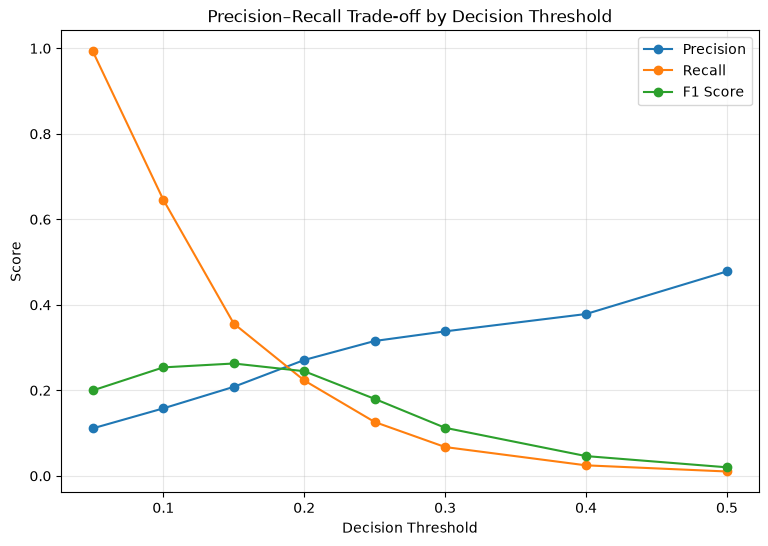

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision–Recall Trade-off by Decision Threshold")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

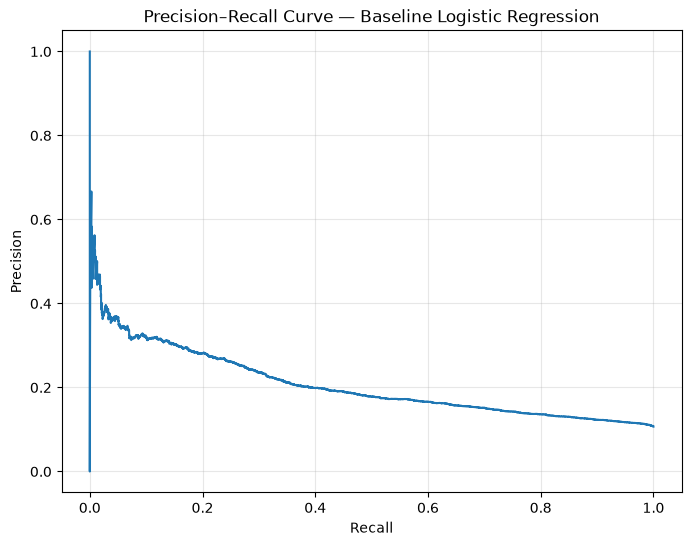

In [47]:
from sklearn.metrics import precision_recall_curve

precision_curve, recall_curve, thresholds_curve = (
    precision_recall_curve(
        y_test,
        y_probability
    )
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Baseline Logistic Regression")
plt.grid(alpha=0.3)

plt.show()